# 02 — Distribuição normal e testes de hipóteses

**Global Solution 2026.2 · MLAM · Citizen Tech** · **Integrantes:** Davi Queiroz Zuolo (RM 571669) · Gustavo Zagato Bottechia (RM 569420) · Daniel Vilela Mana (RM 571632)

Base: `dados/od2017_sp_trabalho.csv` (gerada em `01_preparacao.ipynb`). Variável: **`duracao`**, a duração em minutos da viagem de casa ao trabalho.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import Markdown, display

df = pd.read_csv("dados/od2017_sp_trabalho.csv")
onibus = df[df.usa_onibus == 1]
print(f"trabalhadores: {len(df):,} | vão de ônibus: {len(onibus):,}")

trabalhadores: 19,462 | vão de ônibus: 4,289


## Item 02 — Distribuição normal
Variável aleatória $X$ = duração da viagem de ônibus ao trabalho. Conforme o enunciado, assume-se $X \sim N(\mu, \sigma)$, com $\mu$ e $\sigma$ iguais à média e ao desvio padrão **populacional** dos registros.

Classificação do evento pelo valor da probabilidade:

| Probabilidade | Classificação |
|---|---|
| $P = 0$ | impossível |
| $0 < P < 0{,}5$ | improvável |
| $P = 0{,}5$ | tão provável quanto improvável |
| $0{,}5 < P < 1$ | provável |
| $P = 1$ | certo |

In [2]:
def classificar(p):
    if np.isclose(p, 0): return "impossível"
    if np.isclose(p, 1): return "certo"
    if np.isclose(p, 0.5): return "tão provável quanto improvável"
    return "provável" if p > 0.5 else "improvável"

x = onibus.duracao
mu, sigma, mediana = x.mean(), x.std(ddof=0), x.median()
pa = norm.cdf(mu, mu, sigma)                 # a) P(X < média)
pb = 1 - norm.cdf(mediana, mu, sigma)        # b) P(X > mediana)
display(Markdown(
    f"média μ = **{mu:.2f} min** · desvio padrão σ = **{sigma:.2f} min** · mediana = **{mediana:.1f} min**\n\n"
    f"**a)** P(X < μ) = P(Z < 0) = **{pa:.4f}** → evento **{classificar(pa)}**\n\n"
    f"**b)** z = (mediana − μ)/σ = {(mediana - mu) / sigma:.4f} → P(X > mediana) = 1 − Φ(z) = **{pb:.4f}** → evento **{classificar(pb)}**"))

média μ = **57.77 min** · desvio padrão σ = **31.27 min** · mediana = **50.0 min**

**a)** P(X < μ) = P(Z < 0) = **0.5000** → evento **tão provável quanto improvável**

**b)** z = (mediana − μ)/σ = -0.2483 → P(X > mediana) = 1 − Φ(z) = **0.5981** → evento **provável**

**Interpretação**
- **a)** Na normal, a média divide a curva em duas metades iguais (simetria). Por isso $P(X<\mu)$ é sempre 0,5, qualquer que seja a variável.
- **b)** Se os dados fossem perfeitamente simétricos, a mediana coincidiria com a média e a resposta também seria 0,5. A diferença em relação a 0,5 mede a **assimetria** da duração: há poucas viagens muito longas que puxam a média para cima da mediana.

O gráfico e a comparação abaixo mostram o quanto a hipótese de normalidade se afasta do dado real, o que é uma limitação desta análise.

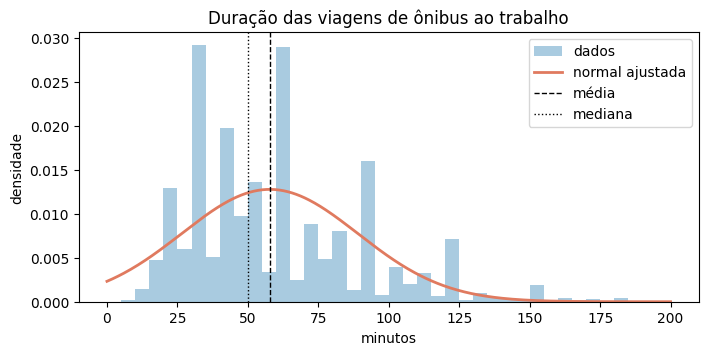

proporção real abaixo da média: 0.529 (normal: 0,500)
proporção real acima da mediana: 0.489 (normal: 0.598)
assimetria: 0.98 (0 em uma normal)


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(x, bins=range(0, 200, 5), density=True, color="#a9cbe0", label="dados")
g = np.linspace(0, 200, 400); ax.plot(g, norm.pdf(g, mu, sigma), color="#e07a5f", lw=2, label="normal ajustada")
ax.axvline(mu, color="k", ls="--", lw=1, label="média"); ax.axvline(mediana, color="k", ls=":", lw=1, label="mediana")
ax.set(title="Duração das viagens de ônibus ao trabalho", xlabel="minutos", ylabel="densidade"); ax.legend(); plt.show()
print(f"proporção real abaixo da média: {(x < mu).mean():.3f} (normal: 0,500)")
print(f"proporção real acima da mediana: {(x > mediana).mean():.3f} (normal: {pb:.3f})")
print(f"assimetria: {x.skew():.2f} (0 em uma normal)")

## Item 03 — Testes de hipóteses para a média (teste Z)
**População de referência:** todos os trabalhadores da base, de todos os modos. A média $\mu_0$ e o desvio padrão $\sigma$ da duração nessa população são os valores de referência (o enunciado pede o desvio padrão populacional dos dados).

Como $\sigma$ é conhecido, a estatística do teste é
$$z = \frac{\bar{x} - \mu_0}{\sigma/\sqrt{n}}$$

As amostras são sorteadas com semente fixa, para que o resultado seja reproduzível.

| | a) | b) |
|---|---|---|
| Pergunta | quem vai de **carro** leva menos tempo que a média geral? | quem vai de **ônibus** leva mais tempo que a média geral? |
| Amostra | 20 trabalhadores que vão de carro | 25 trabalhadores que vão de ônibus |
| $H_0$ | $\mu = \mu_0$ | $\mu = \mu_0$ |
| $H_1$ | $\mu < \mu_0$ (unilateral à esquerda) | $\mu > \mu_0$ (unilateral à direita) |
| $\alpha$ | 6% | 9% |
| Rejeita $H_0$ se | $z < z_{0,06}$ | $z > z_{0,91}$ |

In [4]:
mu0, sigma0 = df.duracao.mean(), df.duracao.std(ddof=0)
print(f"população de referência: μ0 = {mu0:.2f} min | σ = {sigma0:.2f} min | N = {len(df):,}")

def teste_z(amostra, alfa, cauda):
    n, media = len(amostra), amostra.mean()
    z = (media - mu0) / (sigma0 / np.sqrt(n))
    critico = norm.ppf(alfa) if cauda == "esquerda" else norm.ppf(1 - alfa)
    p = norm.cdf(z) if cauda == "esquerda" else 1 - norm.cdf(z)
    rejeita = z < critico if cauda == "esquerda" else z > critico
    return {"n": n, "média amostral": media, "z": z, "z crítico": critico, "p-valor": p, "alfa": alfa,
            "decisão": "rejeita H0" if rejeita else "não rejeita H0"}

a = teste_z(df[df.modo == "carro"].duracao.sample(20, random_state=42), 0.06, "esquerda")
b = teste_z(df[df.modo == "ônibus"].duracao.sample(25, random_state=42), 0.09, "direita")
display(pd.DataFrame({"a) carro, cauda esquerda": a, "b) ônibus, cauda direita": b}))

população de referência: μ0 = 39.47 min | σ = 31.53 min | N = 19,462


,"a) carro, cauda esquerda","b) ônibus, cauda direita"
n,20,25
média amostral,27.55,69.28
z,-1.690022,4.727427
z crítico,-1.554774,1.340755
p-valor,0.045512,0.000001
alfa,0.06,0.09
decisão,rejeita H0,rejeita H0


In [5]:
def conclusao(r, grupo, sentido):
    if r["decisão"] == "rejeita H0":
        return (f"z = {r['z']:.2f} está na região crítica (p-valor {r['p-valor']:.4f} < {r['alfa']}). **Rejeita-se H0**: ao nível de "
                f"{r['alfa']:.0%}, há evidência de que a duração média de quem vai de {grupo} é {sentido} que a média geral.")
    return (f"z = {r['z']:.2f} não está na região crítica (p-valor {r['p-valor']:.4f} > {r['alfa']}). **Não se rejeita H0**: com esta amostra "
            f"de {r['n']}, não há evidência suficiente de que a duração média de quem vai de {grupo} seja {sentido} que a média geral.")
display(Markdown("**a)** " + conclusao(a, "carro", "menor") + "\n\n**b)** " + conclusao(b, "ônibus", "maior")))

**a)** z = -1.69 está na região crítica (p-valor 0.0455 < 0.06). **Rejeita-se H0**: ao nível de 6%, há evidência de que a duração média de quem vai de carro é menor que a média geral.

**b)** z = 4.73 está na região crítica (p-valor 0.0000 < 0.09). **Rejeita-se H0**: ao nível de 9%, há evidência de que a duração média de quem vai de ônibus é maior que a média geral.

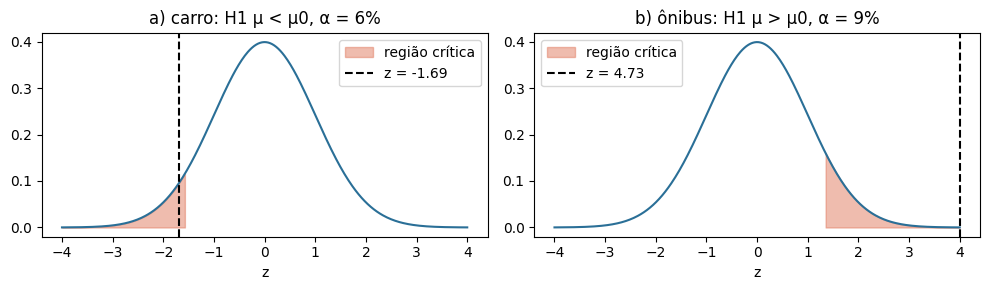

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3))
g = np.linspace(-4, 4, 400)
for ax, r, cauda, titulo in ((eixos[0], a, "esquerda", "a) carro: H1 μ < μ0, α = 6%"), (eixos[1], b, "direita", "b) ônibus: H1 μ > μ0, α = 9%")):
    ax.plot(g, norm.pdf(g), color="#2a6f97")
    regiao = g <= r["z crítico"] if cauda == "esquerda" else g >= r["z crítico"]
    ax.fill_between(g, norm.pdf(g), where=regiao, color="#e07a5f", alpha=0.5, label="região crítica")
    ax.axvline(np.clip(r["z"], -4, 4), color="k", ls="--", label=f"z = {r['z']:.2f}"); ax.set(title=titulo, xlabel="z"); ax.legend()
plt.tight_layout(); plt.show()

**Como ler os resultados**
- "Não rejeitar $H_0$" **não** prova que as médias são iguais. Com amostras de 20 ou 25 e um desvio padrão populacional alto, o teste só detecta diferenças grandes. É uma limitação do tamanho da amostra fixado pelo enunciado.
- O resultado depende da amostra sorteada. A semente fixa garante que qualquer pessoa obtenha os mesmos números ao rodar o notebook.
- O teste Z pressupõe normalidade da média amostral. A duração é assimétrica (item 02), e com $n$ de 20 a 25 o Teorema Central do Limite só garante isso de forma aproximada.

**Ligação com o problema:** a diferença de tempo entre ônibus e a média geral é o custo que o trabalhador dependente do ônibus paga todos os dias, e é o que a redistribuição da frota do projeto Linha Certa busca reduzir.